# 6. The data-processing inequality

**Cover and Thomas, Section 2.8.**

$X, Y, Z$ form a **Markov chain** $X \to Y \to Z$ when

$$p(x,y,z) = p(x)\,p(y\mid x)\,p(z \mid y),$$

that is, $Z$ depends on $X$ only through $Y$.

**Theorem 2.8.1 (data-processing inequality).** If $X \to Y \to Z$, then

$$I(X;Y) \;\ge\; I(X;Z).$$

**Corollary.** In particular $I(X;Y) \ge I(X;g(Y))$ for any function $g$.

**Corollary.** If $X \to Y \to Z$, then $I(X;Y \mid Z) \le I(X;Y)$.

The proof is two lines of the chain rule:

$$I(X;Y,Z) = I(X;Z) + \underbrace{I(X;Y\mid Z)}_{\ge 0}
= I(X;Y) + \underbrace{I(X;Z\mid Y)}_{=\,0 \text{ by Markovity}} .$$

No processing of $Y$, deterministic or random, can create information about
$X$ that was not already in $Y$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(6)

## 6.1 Building a Markov chain

A channel is a matrix `W[i, j]` $= p(\text{output} = j \mid \text{input} = i)$,
whose rows sum to 1. A Markov chain is a starting distribution followed by a
list of channels.

In [2]:
def bsc(eps):
    """Binary symmetric channel: flips the bit with probability eps."""
    return np.array([[1 - eps, eps],
                     [eps, 1 - eps]])


def random_channel(n_in, n_out, rng):
    """A channel with random rows."""
    return np.array([rng.dirichlet(np.ones(n_out)) for _ in range(n_in)])


def markov_joint(pX, W1, W2):
    """p(x, y, z) = p(x) W1[x, y] W2[y, z]."""
    pX = np.asarray(pX, dtype=float)
    return pX[:, None, None] * np.asarray(W1)[:, :, None] * np.asarray(W2)[None, :, :]


pX = np.array([0.5, 0.5])
W1 = bsc(0.10)          # X -> Y
W2 = bsc(0.25)          # Y -> Z
P3 = markov_joint(pX, W1, W2)

print("shape:", P3.shape, "   total probability:", P3.sum())

shape: (2, 2, 2)    total probability: 1.0


Every information quantity is obtained by summing the 3-D table down to the
variables of interest.

In [3]:
P_XY = P3.sum(axis=2)       # p(x, y)
P_XZ = P3.sum(axis=1)       # p(x, z)
P_YZ = P3.sum(axis=0)       # p(y, z)

I_XY = it.mutual_information(P_XY)
I_XZ = it.mutual_information(P_XZ)
I_YZ = it.mutual_information(P_YZ)

print(f"I(X;Y) = {I_XY:.6f} bits")
print(f"I(X;Z) = {I_XZ:.6f} bits")
print(f"I(Y;Z) = {I_YZ:.6f} bits")
print()
it.check("data processing: I(X;Y) >= I(X;Z)", I_XY >= I_XZ - 1e-12)
it.check("also I(Y;Z) >= I(X;Z)", I_YZ >= I_XZ - 1e-12)

I(X;Y) = 0.531004 bits
I(X;Z) = 0.118709 bits
I(Y;Z) = 0.188722 bits

[PASS] data processing: I(X;Y) >= I(X;Z)
[PASS] also I(Y;Z) >= I(X;Z)


True

## 6.2 The proof, checked term by term

$$I(X;Y,Z) = I(X;Z) + I(X;Y \mid Z) = I(X;Y) + I(X;Z \mid Y).$$

Markovity is exactly the statement $I(X;Z\mid Y) = 0$.

In [4]:
def H_of(P, axes):
    axes = list(axes)
    if len(axes) == 0:
        return 0.0
    drop = tuple(a for a in range(P.ndim) if a not in axes)
    return it.entropy(P.sum(axis=drop) if drop else P)


def I_cond(P, x_axes, y_axes, z_axes):
    """I(X ; Y | Z) with each group given by a list of axes."""
    x_axes, y_axes, z_axes = list(x_axes), list(y_axes), list(z_axes)
    return (H_of(P, x_axes + z_axes) + H_of(P, y_axes + z_axes)
            - H_of(P, x_axes + y_axes + z_axes) - H_of(P, z_axes))


I_X_YZ  = I_cond(P3, [0], [1, 2], [])
I_X_Y_g_Z = I_cond(P3, [0], [1], [2])
I_X_Z_g_Y = I_cond(P3, [0], [2], [1])

print(f"I(X; Y,Z)   = {I_X_YZ:.8f}")
print(f"I(X;Z) + I(X;Y|Z) = {I_XZ + I_X_Y_g_Z:.8f}")
print(f"I(X;Y) + I(X;Z|Y) = {I_XY + I_X_Z_g_Y:.8f}")
print()
print(f"I(X;Z|Y)    = {I_X_Z_g_Y:.3e}    (zero, because X -> Y -> Z)")
print(f"I(X;Y|Z)    = {I_X_Y_g_Z:.8f}    (non-negative, and it is the gap)")
print(f"I(X;Y) - I(X;Z) = {I_XY - I_XZ:.8f}")

it.check("I(X;Z|Y) = 0 for a Markov chain", abs(I_X_Z_g_Y) < 1e-12)
it.check("the gap I(X;Y) - I(X;Z) equals I(X;Y|Z)",
         np.isclose(I_XY - I_XZ, I_X_Y_g_Z))

I(X; Y,Z)   = 0.53100441
I(X;Z) + I(X;Y|Z) = 0.53100441
I(X;Y) + I(X;Z|Y) = 0.53100441

I(X;Z|Y)    = 4.441e-16    (zero, because X -> Y -> Z)
I(X;Y|Z)    = 0.41229531    (non-negative, and it is the gap)
I(X;Y) - I(X;Z) = 0.41229531
[PASS] I(X;Z|Y) = 0 for a Markov chain
[PASS] the gap I(X;Y) - I(X;Z) equals I(X;Y|Z)


True

## 6.3 A cascade of noisy channels

Send a fair bit through $k$ identical binary symmetric channels in a row. The
composition of $k$ channels with crossover $\varepsilon$ is again a binary
symmetric channel, with crossover

$$\varepsilon_k = \frac{1 - (1-2\varepsilon)^k}{2},$$

so the information about the original bit decays to zero. This is the
data-processing inequality applied over and over.

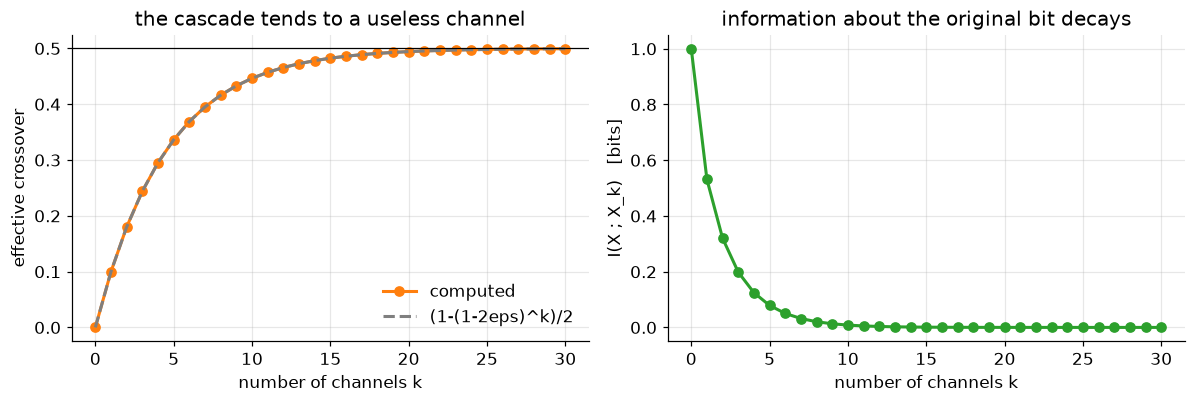

[PASS] the sequence I(X ; X_k) is non-increasing
[PASS] effective crossover matches the closed formula


True

In [5]:
eps = 0.10
k_max = 30

W = bsc(eps)
current = np.eye(2)                  # the identity channel, k = 0
I_values, eps_values = [], []
for k in range(k_max + 1):
    P = np.array([0.5, 0.5])[:, None] * current
    I_values.append(it.mutual_information(P))
    eps_values.append(current[0, 1])
    current = current @ W            # one more channel in the cascade

ks = np.arange(k_max + 1)
formula = (1 - (1 - 2*eps)**ks) / 2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(ks, eps_values, "o-", color=it.COLORS["cond"], label="computed")
axes[0].plot(ks, formula, "--", color=it.COLORS["bound"], label="(1-(1-2eps)^k)/2")
axes[0].axhline(0.5, color="black", linewidth=0.8)
axes[0].set_xlabel("number of channels k")
axes[0].set_ylabel("effective crossover")
axes[0].set_title("the cascade tends to a useless channel")
axes[0].legend()

axes[1].plot(ks, I_values, "o-", color=it.COLORS["I"])
axes[1].set_xlabel("number of channels k")
axes[1].set_ylabel("I(X ; X_k)   [bits]")
axes[1].set_title("information about the original bit decays")
plt.tight_layout()
plt.show()

it.check("the sequence I(X ; X_k) is non-increasing",
         all(I_values[i] >= I_values[i+1] - 1e-12 for i in range(k_max)))
it.check("effective crossover matches the closed formula",
         np.allclose(eps_values, formula))

## 6.4 Functions of the data: $I(X;Y) \ge I(X;g(Y))$

Suppose $Y$ is a noisy measurement of $X$ on a scale of eight levels, and we
decide to report only a coarse version $g(Y) = \lfloor Y/2 \rfloor$ on four
levels. Coarsening can only lose information.

In [6]:
pX = np.array([0.5, 0.5])
W = np.array([                     # p(y | x), eight output levels
    [0.30, 0.25, 0.20, 0.10, 0.07, 0.04, 0.03, 0.01],
    [0.01, 0.03, 0.04, 0.07, 0.10, 0.20, 0.25, 0.30],
])
P_XY = pX[:, None] * W


def apply_function(P, g_values, n_groups):
    """Table of (X, g(Y)) obtained by adding up the columns of each group."""
    out = np.zeros((P.shape[0], n_groups))
    for j, g in enumerate(g_values):
        out[:, g] += P[:, j]
    return out


g_coarse = [j // 2 for j in range(8)]      # 8 levels -> 4 levels
g_binary = [j // 4 for j in range(8)]      # 8 levels -> 2 levels

P_Xg = apply_function(P_XY, g_coarse, 4)
P_Xb = apply_function(P_XY, g_binary, 2)

print(f"I(X;Y)          (8 levels) = {it.mutual_information(P_XY):.6f} bits")
print(f"I(X;g(Y))       (4 levels) = {it.mutual_information(P_Xg):.6f} bits")
print(f"I(X;g(Y))       (2 levels) = {it.mutual_information(P_Xb):.6f} bits")
it.check("I(X;Y) >= I(X;g(Y)) for the 4-level quantizer",
         it.mutual_information(P_XY) >= it.mutual_information(P_Xg) - 1e-12)
it.check("more coarsening loses more",
         it.mutual_information(P_Xg) >= it.mutual_information(P_Xb) - 1e-12)

I(X;Y)          (8 levels) = 0.476553 bits
I(X;g(Y))       (4 levels) = 0.444997 bits
I(X;g(Y))       (2 levels) = 0.390160 bits
[PASS] I(X;Y) >= I(X;g(Y)) for the 4-level quantizer
[PASS] more coarsening loses more


True

Not every binary quantizer is equally bad. The cell below tries every way of
splitting the eight levels into two groups and shows how much information
survives. The best split is the one a good detector would choose.

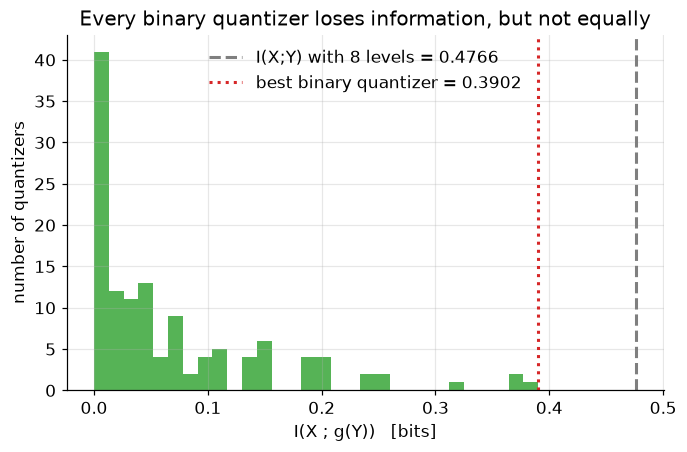

[PASS] no quantizer beats the raw data


True

In [7]:
results = []
for mask in range(1, 2**7):                      # 2^8/2 splits, up to symmetry
    bits = [(mask >> j) & 1 for j in range(8)]
    P_split = apply_function(P_XY, bits, 2)
    results.append(it.mutual_information(P_split))

results = np.array(results)
plt.hist(results, bins=30, color=it.COLORS["I"], alpha=0.8)
plt.axvline(it.mutual_information(P_XY), color=it.COLORS["bound"], linestyle="--",
            label=f"I(X;Y) with 8 levels = {it.mutual_information(P_XY):.4f}")
plt.axvline(results.max(), color=it.COLORS["D"], linestyle=":",
            label=f"best binary quantizer = {results.max():.4f}")
plt.xlabel("I(X ; g(Y))   [bits]")
plt.ylabel("number of quantizers")
plt.title("Every binary quantizer loses information, but not equally")
plt.legend()
plt.show()

it.check("no quantizer beats the raw data",
         results.max() <= it.mutual_information(P_XY) + 1e-12)

## 6.5 Conditioning on something downstream

**Corollary.** If $X \to Y \to Z$ then $I(X;Y\mid Z) \le I(X;Y)$.

**But this needs the Markov property.** The book's counterexample: $X$ and $Y$
independent fair bits, $Z = X + Y$. Then $I(X;Y) = 0$ while
$I(X;Y\mid Z) = 1/2$ bit.

In [8]:
print("Markov chain X -> Y -> Z:")
print(f"  I(X;Y)     = {I_XY:.6f}")
print(f"  I(X;Y | Z) = {I_X_Y_g_Z:.6f}")
it.check("  I(X;Y|Z) <= I(X;Y)", I_X_Y_g_Z <= I_XY + 1e-12)

print("\nNot a Markov chain: Z = X + Y with X, Y independent fair bits")
P_sum = np.zeros((2, 2, 3))
for x in (0, 1):
    for y in (0, 1):
        P_sum[x, y, x + y] = 0.25
print(f"  I(X;Y)     = {I_cond(P_sum, [0], [1], []):.6f}")
print(f"  I(X;Y | Z) = {I_cond(P_sum, [0], [1], [2]):.6f}")
it.check("  here conditioning increases the mutual information",
         I_cond(P_sum, [0], [1], [2]) > I_cond(P_sum, [0], [1], []))
it.check("  and indeed X -> Y -> Z fails: I(X;Z|Y) is not 0",
         I_cond(P_sum, [0], [2], [1]) > 1e-9,
         f"I(X;Z|Y) = {I_cond(P_sum, [0], [2], [1]):.6f}")

Markov chain X -> Y -> Z:
  I(X;Y)     = 0.531004
  I(X;Y | Z) = 0.412295
[PASS]   I(X;Y|Z) <= I(X;Y)

Not a Markov chain: Z = X + Y with X, Y independent fair bits
  I(X;Y)     = 0.000000
  I(X;Y | Z) = 0.500000
[PASS]   here conditioning increases the mutual information
[PASS]   and indeed X -> Y -> Z fails: I(X;Z|Y) is not 0   I(X;Z|Y) = 1.000000


True

## 6.6 The inequality on random Markov chains

Random alphabets, random starting distribution, random channels.

In [9]:
n_tests = 5000
worst = np.inf
for _ in range(n_tests):
    nx, ny, nz = (int(rng.integers(2, 6)) for _ in range(3))
    P3r = markov_joint(it.random_pmf(nx, rng),
                       random_channel(nx, ny, rng),
                       random_channel(ny, nz, rng))
    gap = it.mutual_information(P3r.sum(axis=2)) - it.mutual_information(P3r.sum(axis=1))
    worst = min(worst, gap)

it.check(f"I(X;Y) - I(X;Z) >= 0 on {n_tests} random Markov chains", worst >= -1e-12,
         f"smallest gap seen: {worst:.3e}")

[PASS] I(X;Y) - I(X;Z) >= 0 on 5000 random Markov chains   smallest gap seen: 4.178e-07


True

## 6.7 The same thing with data instead of formulas

Simulate the chain, count the triples, and estimate the mutual informations
from the counts. With enough data, the inequality shows up in the estimates
as well.

In [10]:
n = 20_000
eps1, eps2 = 0.10, 0.25

x = rng.choice(2, size=n, p=[0.5, 0.5])          # the original bit
y = np.where(rng.random(n) < eps1, 1 - x, x)     # after the first channel
z = np.where(rng.random(n) < eps2, 1 - y, y)     # after the second channel


def table_from_samples(u, v, nu, nv):
    """Estimate p(u, v) by counting how often each pair occurs."""
    T = np.zeros((nu, nv))
    for a, b in zip(u, v):
        T[a, b] += 1
    return T / len(u)


I_XY_hat = it.mutual_information(table_from_samples(x, y, 2, 2))
I_XZ_hat = it.mutual_information(table_from_samples(x, z, 2, 2))

print(f"estimated I(X;Y) = {I_XY_hat:.5f}   exact = {I_XY:.5f}")
print(f"estimated I(X;Z) = {I_XZ_hat:.5f}   exact = {I_XZ:.5f}")
it.check("the inequality also holds for the estimates", I_XY_hat >= I_XZ_hat)

estimated I(X;Y) = 0.53235   exact = 0.53100
estimated I(X;Z) = 0.11594   exact = 0.11871
[PASS] the inequality also holds for the estimates


True

## Things to try

1. In Section 6.3, set `eps = 0.5` for one channel in the middle of the
   cascade. What happens to all the later mutual informations, and why?
2. In Section 6.4, design by hand the binary quantizer that achieves the
   maximum found by the search. How does it relate to the likelihood ratio
   $p(y \mid X=1)/p(y \mid X=0)$?
3. Build a chain $X \to Y \to Z$ in which $I(X;Y) = I(X;Z)$ exactly. What must
   the second channel be? (Equality holds when $X \to Z \to Y$ is also a
   Markov chain.)
4. Take a binary erasure channel followed by a second one and plot
   $I(X;X_k)$ for the cascade. Compare the decay with the symmetric case.